# Восстановление уравнений Лоренца с помощью сети Колмогорова–Арнольда

*Учебное приложение к главе 4 пособия «Нейронные сети для инженеров» (связь с главой 10 «Динамические системы»)*

Система Лоренца — классическая модель хаотической динамики:

$$
\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z,
\qquad \sigma=10,\ \rho=28,\ \beta=8/3 .
$$

Здесь $x,y,z$ — переменные состояния, точка обозначает производную по времени $t$. **Задача идентификации:** по наблюдениям состояния $(x,y,z)$ и скорости его изменения $(\dot x,\dot y,\dot z)$ восстановить правые части уравнений — векторное поле системы, — а затем и сами формулы.

Пример показывает сразу несколько линий главы 4:

| Вопрос | Где в главе |
|---|---|
| правая часть $\dot x$ аддитивна, а $\dot y$, $\dot z$ содержат произведения $xz$, $xy$ | п. 4.2.2, пример 4.1 |
| данные на аттракторе не определяют функцию во всём пространстве | п. 3.1.3, 4.4.6 |
| символизация + уточнение МНК превращают сеть в формулу | п. 4.3.4 |
| когда достаточно МНК с фиксированным базисом | глава 3, блокноты `ch03_Lorenz_SINDy.ipynb` и `KAN_примеры.ipynb` |
| точное поле ещё не даёт долгосрочного прогноза хаотической траектории | глава 10 |

**Связь с главой 3.** Тот же пример с другой стороны разобран в блокноте главы 3 `ch03_Lorenz_SINDy.ipynb`. Там уравнения восстанавливаются методом SINDy — МНК в библиотеке мономов с пороговым отсечением малых коэффициентов. Если вид правых частей известен заранее (полиномы), этот метод восстанавливает систему Лоренца точно, одной линейной задачей и по данным только с аттрактора. Там же разобраны оценка производных по зашумлённым измерениям, влияние размера библиотеки и горизонт прогноза хаотической траектории. Здесь задача ставится иначе: что может сеть, если вид правых частей **неизвестен**.

**Как запустить.** Блокнот лежит в одной папке с модулем `kan.py`. Нужны NumPy и Matplotlib. Полный прогон занимает около 5 минут: обучаются полтора десятка небольших сетей, включая опыт с шумом.

**Содержание**
1. [Моделирование аттрактора](#s1)
2. [Два набора данных](#s2)
3. [KAN на данных с аттрактора](#s3)
4. [KAN на данных, покрывающих область](#s4)
5. [Функции на связях и символизация](#s5)
6. [Интегрирование выученных систем](#s6)
7. [Опыт с шумом](#s7n)
8. [Выводы](#s7)

In [1]:
import time, itertools
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import Markdown, display

from kan import KAN, train

plt.rcParams.update({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 10,
                     'axes.linewidth': 0.7, 'legend.frameon': False, 'figure.dpi': 110})
_sf = mticker.ScalarFormatter.__call__
mticker.ScalarFormatter.__call__ = lambda self, x, pos=None: _sf(self, x, pos).replace('.', ',')
GREY = '0.92'
num = lambda v, d=3: f'{v:.{d}g}'.replace('.', ',')
mnum = lambda v, d=4: f'{v:.{d}g}'.replace('.', '{,}')
rmse = lambda p, y: float(np.sqrt(np.mean((p - y) ** 2)))

<a id="s1"></a>
## 1. Моделирование аттрактора

Уравнения интегрируются методом Рунге–Кутты 4-го порядка с шагом $\Delta t=0{,}01$. Начальный участок длиной 10 единиц времени отбрасывается, чтобы траектория успела выйти на аттрактор.

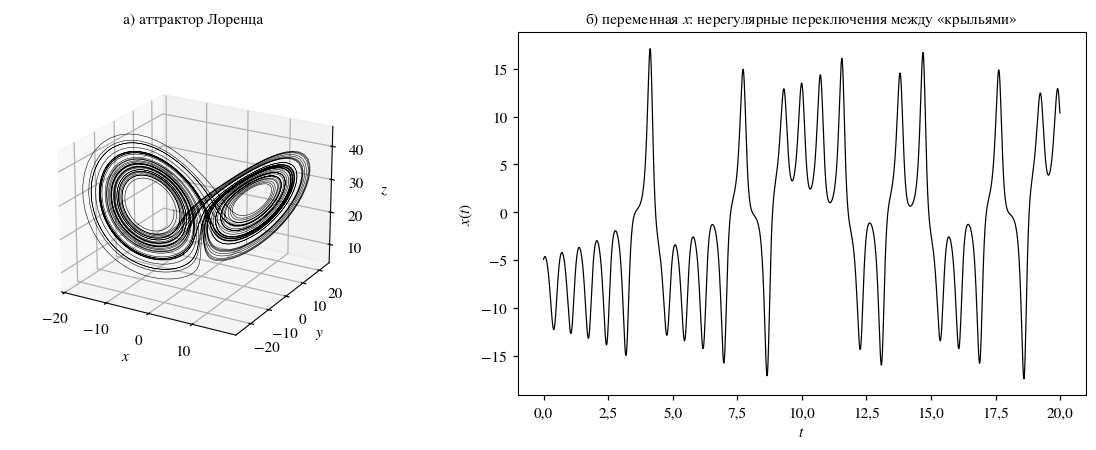

In [2]:
SIGMA, RHO, BETA = 10.0, 28.0, 8.0 / 3.0
NAMES = [r'\dot x', r'\dot y', r'\dot z']

def lorenz(s):
    x, y, z = s[..., 0], s[..., 1], s[..., 2]
    return np.stack([SIGMA * (y - x), x * (RHO - z) - y, x * y - BETA * z], axis=-1)

def rk4(field, s0, dt, n):
    out = np.empty((n + 1, 3)); s = np.array(s0, float); out[0] = s
    for i in range(n):
        k1 = field(s); k2 = field(s + dt / 2 * k1); k3 = field(s + dt / 2 * k2); k4 = field(s + dt * k3)
        s = s + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4); out[i + 1] = s
    return out

DT = 0.01
traj = rk4(lorenz, [1.0, 1.0, 1.0], DT, 6000)[1000:]          # 50 единиц времени после переходного участка

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot(*traj.T, color='black', lw=0.35)
ax.set_xlabel('$x$'); ax.set_ylabel('$y$'); ax.set_zlabel('$z$'); ax.view_init(elev=22, azim=-60)
ax.set_title('а) аттрактор Лоренца', fontsize=10); ax.set_box_aspect(None, zoom=0.85)
ax = fig.add_subplot(1, 2, 2)
tt = np.arange(len(traj)) * DT
ax.plot(tt[:2000], traj[:2000, 0], 'k-', lw=0.8)
ax.set_xlabel('$t$'); ax.set_ylabel('$x(t)$'); ax.set_title('б) переменная $x$: нерегулярные переключения между «крыльями»', fontsize=10)
fig.tight_layout(); plt.show()

<a id="s2"></a>
## 2. Два набора данных

Скорости $(\dot x,\dot y,\dot z)$ в учебной постановке вычисляются точно по уравнениям; в эксперименте их пришлось бы получать численным дифференцированием измеренной траектории (это заметно усиливает шум — см. задание в конце).

Сравним два способа собрать данные:
* **A — с аттрактора:** точки одной длинной траектории. Так выглядят данные наблюдения за системой, предоставленной самой себе.
* **B — покрывающие область:** точки, равномерно распределённые в прямоугольной области, которую занимает аттрактор. Так выглядят данные эксперимента, в котором систему запускают из разных начальных состояний.

В каждом наборе 600 обучающих, 200 валидационных и 1000 тестовых точек. Входы нормируются на $[-1,1]$ по границам области, цели — делением на стандартное отклонение каждой компоненты.

**Шум в данных.** Параметры в следующей ячейке задают уровень шума для разделов 3–6:
* `NOISE_DERIV` — шум скоростей $(\dot x,\dot y,\dot z)$ в долях стандартного отклонения каждой компоненты; моделирует ошибку численного дифференцирования;
* `NOISE_STATE` — шум измерения состояния $(x,y,z)$ в долях размаха области по каждой координате.

Шум гауссов, добавляется только к обучающим и валидационным данным; тестовые данные остаются точными, чтобы оценивать восстановление истинного поля. Чтобы изменить уровень, исправьте значения и перезапустите блокнот целиком (*Kernel → Restart & Run All*). По умолчанию шума нет; систематическое сравнение уровней шума — в разделе 7.

In [3]:
NOISE_DERIV = 0.0      # например, 0.01 = 1 % от стандартного отклонения скорости
NOISE_STATE = 0.0      # например, 0.002 = 0,2 % от размаха области
NOISE_SEED = 314159

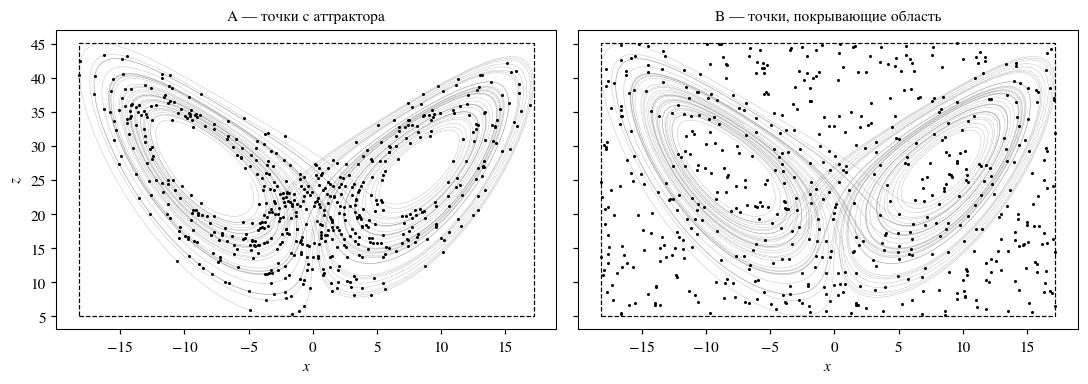

Область: $x\in[-18{,}2;\,17{,}2]$, $y\in[-24{,}6;\,22{,}7]$, $z\in[5{,}1;\,45{,}1]$. Проекция на плоскость $(x,z)$; серым — траектория.

In [4]:
rng = np.random.default_rng(0)
LO, HI = traj.min(0), traj.max(0)
norm = lambda s: 2 * (s - LO) / (HI - LO) - 1
P_A = traj[rng.permutation(len(traj))[:1800]]
P_B = np.random.default_rng(5).uniform(LO, HI, (1800, 3))
SCALE = lorenz(P_A).std(0)

def split(P, noise_deriv=0.0, noise_state=0.0, seed=314159):
    # шум добавляется только к обучающей и валидационной частям; тест остаётся точным
    r = np.random.default_rng(seed)
    Pn = P.copy(); Fn = lorenz(P)
    Pn[:800] += noise_state * (HI - LO) * r.standard_normal((800, 3))
    Fn[:800] += noise_deriv * SCALE * r.standard_normal((800, 3))
    X, F = norm(Pn), Fn / SCALE
    return {'train': (X[:600], F[:600]), 'val': (X[600:800], F[600:800]), 'test': (X[800:], F[800:]),
            'phys': P, 'P_train': Pn[:600], 'dX_train': Fn[:600]}
DA = split(P_A, NOISE_DERIV, NOISE_STATE, NOISE_SEED)
DB = split(P_B, NOISE_DERIV, NOISE_STATE, NOISE_SEED)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, P, ttl in [(axs[0], P_A, 'A — точки с аттрактора'), (axs[1], P_B, 'B — точки, покрывающие область')]:
    ax.plot(traj[:, 0], traj[:, 2], color='0.75', lw=0.3, zorder=0)
    ax.plot(P[:600, 0], P[:600, 2], '.', color='black', ms=2)
    ax.add_patch(plt.Rectangle((LO[0], LO[2]), HI[0] - LO[0], HI[2] - LO[2], fill=False, ls='--', lw=0.8))
    ax.set_xlabel('$x$'); ax.set_title(ttl, fontsize=10)
axs[0].set_ylabel('$z$'); fig.tight_layout(); plt.show()
display(Markdown(f'Область: $x\\in[{mnum(LO[0], 3)};\\,{mnum(HI[0], 3)}]$, $y\\in[{mnum(LO[1], 3)};\\,{mnum(HI[1], 3)}]$, '
                 f'$z\\in[{mnum(LO[2], 3)};\\,{mnum(HI[2], 3)}]$. Проекция на плоскость $(x,z)$; серым — траектория.'))

**Что наблюдается в каждой точке набора B.** Наблюдение — это вектор скорости $(\dot x,\dot y,\dot z)$, то есть значение векторного поля системы в этой точке. Поле определено во всём пространстве: если поставить систему в точку вне аттрактора, она начнёт двигаться в направлении этого вектора и через переходный процесс притянется к аттрактору. Ниже поле показано в 60 случайных точках набора B; все стрелки одной длины и показывают только направление, а модуль скорости передан оттенком.

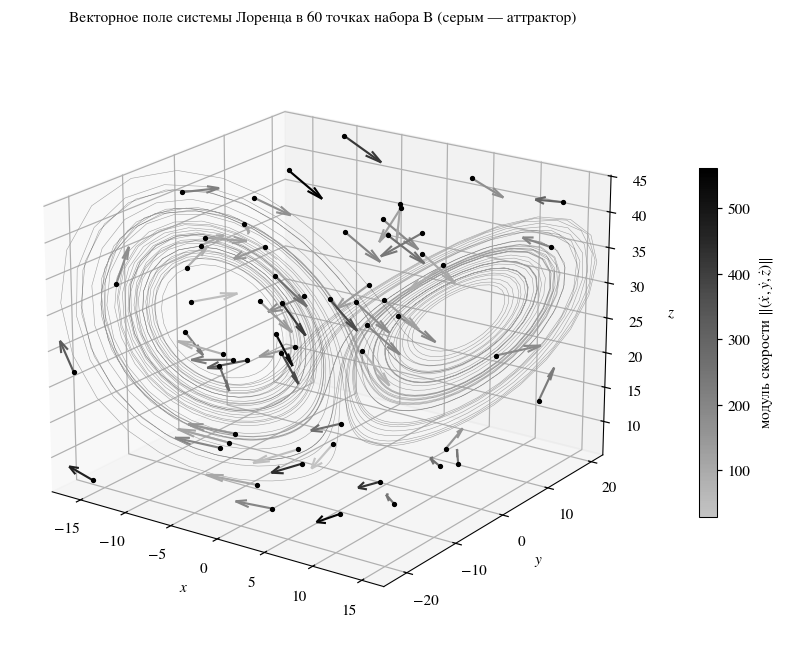

In [5]:
sub = np.random.default_rng(2).choice(600, 60, replace=False)
Pq = P_B[sub]; Vq = lorenz(Pq)
speed = np.linalg.norm(Vq, axis=1)
Uq = Vq / speed[:, None]                                  # единичные направления

fig = plt.figure(figsize=(9.5, 7.5))
ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
ax.plot(*traj[::2].T, color='0.62', lw=0.35, zorder=1)
shade = plt.cm.Greys(0.35 + 0.65 * (speed - speed.min()) / np.ptp(speed))
L_ARROW = 5.0
for p, d, col in zip(Pq, Uq, shade):
    ax.quiver(*p, *(d * L_ARROW), color=col, lw=1.4, arrow_length_ratio=0.35, zorder=5)
ax.scatter(*Pq.T, s=6, color='black', depthshade=False, zorder=6)
ax.set_xlabel('$x$'); ax.set_ylabel('$y$'); ax.set_zlabel('$z$')
ax.set_xlim(LO[0], HI[0]); ax.set_ylim(LO[1], HI[1]); ax.set_zlim(LO[2], HI[2])
ax.view_init(elev=20, azim=-55); ax.set_box_aspect(None, zoom=1.0)
sm = plt.cm.ScalarMappable(cmap=plt.cm.colors.ListedColormap(plt.cm.Greys(np.linspace(0.35, 1, 256))),
                           norm=plt.Normalize(speed.min(), speed.max()))
fig.colorbar(sm, ax=ax, shrink=0.55, pad=0.08, label=r'модуль скорости $\|(\dot x,\dot y,\dot z)\|$')
ax.set_title('Векторное поле системы Лоренца в 60 точках набора B (серым — аттрактор)', fontsize=10)
plt.show()

Стрелки вне аттрактора показывают, куда система движется из этих состояний: вращение вокруг двух неустойчивых равновесий $(\pm\sqrt{\beta(\rho-1)},\,\pm\sqrt{\beta(\rho-1)},\,\rho-1)$ в центрах «крыльев» и притяжение к аттрактору сверху и снизу по $z$. Именно эту информацию о поле *вне* аттрактора данные A не содержат. В реальном эксперименте такие наблюдения получают, запуская систему из разных начальных состояний: природную систему, за которой можно только наблюдать, в такие точки не поставить.

<a id="s3"></a>
## 3. KAN на данных с аттрактора

Будем считать, что вид правых частей неизвестен: библиотеки функций, как в блокноте главы 3, у нас нет.

Для каждой правой части обучаем отдельную сеть двух архитектур:
* **3–1** — один слой, аддитивная модель $g_1(x)+g_2(y)+g_3(z)$;
* **3–2–1** — со скрытым слоем из двух узлов; этого достаточно для произведения: $xz=\tfrac14(x+z)^2-\tfrac14(x-z)^2$ (пример 4.1).

Точность проверяем на двух тестовых выборках: с аттрактора (A) и из всей области (B).

In [6]:
def fit_kan(sizes, D, stages, seed=0):
    net = KAN(sizes, G=5); r = np.random.default_rng(seed)
    for L in net.layers:
        L.c[...] = r.normal(0, 0.1, L.c.shape); L.wb[...] = r.normal(0, 1 / np.sqrt(L.nin), L.wb.shape)
    hist = []
    for st in stages:
        if 'G' in st: net.update_grid(D['train'][0], st['G'])
        train(net, D['train'][0], D['train'][1][:, [D['j']]], D['val'][0], D['val'][1][:, [D['j']]], st['epochs'], st['lr'], hist)
    return net

SHORT = [dict(epochs=3000, lr=0.01)]
LONG = [dict(epochs=3000, lr=0.01), dict(G=10, epochs=2000, lr=0.003)]
t0 = time.perf_counter(); nets_A = {}; rows = ''
for j in range(3):
    for sizes in ([3, 1], [3, 2, 1]):
        net = fit_kan(sizes, dict(DA, j=j), SHORT)
        nets_A[(j, len(sizes))] = net
        eA = rmse(net.forward(DA['test'][0])[:, 0], DA['test'][1][:, j])
        eB = rmse(net.forward(DB['test'][0])[:, 0], DB['test'][1][:, j])
        arch = '–'.join(map(str, sizes))
        rows += f'| ${NAMES[j]}$ | {arch} | {net.n_params()} | {num(eA)} | {num(eB)} |\n'
print(f'обучено за {time.perf_counter() - t0:.0f} с')
display(Markdown('Относительная RMSE (в долях стандартного отклонения компоненты):\n\n'
                 '| Компонента | Архитектура | Парам. | тест A (аттрактор) | тест B (вся область) |\n|---|---|---|---|---|\n' + rows))

обучено за 94 с


Относительная RMSE (в долях стандартного отклонения компоненты):

| Компонента | Архитектура | Парам. | тест A (аттрактор) | тест B (вся область) |
|---|---|---|---|---|
| $\dot x$ | 3–1 | 30 | 0,000362 | 0,00124 |
| $\dot x$ | 3–2–1 | 80 | 0,0112 | 2,47 |
| $\dot y$ | 3–1 | 30 | 0,109 | 4,33 |
| $\dot y$ | 3–2–1 | 80 | 0,0125 | 1,83 |
| $\dot z$ | 3–1 | 30 | 0,0234 | 2,69 |
| $\dot z$ | 3–2–1 | 80 | 0,00919 | 2,12 |


Здесь два важных наблюдения.

1. **Аддитивная сеть 3–1 хорошо описывает $\dot x=\sigma(y-x)$, но не $\dot y$ с произведением $xz$**: смешанная разность произведения отлична от нуля (п. 4.2.2). Для $\dot z=xy-\beta z$ аддитивная сеть на аттракторе даёт ошибку всего около 2 %: на аттракторе переменные $x$ и $y$ сильно связаны, и произведение $xy$ вдоль траектории почти сводится к функции одной переменной.
2. **Все сети, обученные на аттракторе, ошибаются во всей области в разы** — даже 3–2–1, и даже для линейной правой части $\dot x$. Аттрактор занимает лишь тонкую часть области, а вне него сеть ничего не знает о поле: данные с аттрактора **не определяют** функцию в остальном пространстве. Это та же проблема экстраполяции, что в п. 4.4.6, только «за границей данных» оказывается почти вся область.

Полиномиальный МНК этой проблемы не имеет (блокнот главы 3, шаг 2): класс функций в нём узкий — несколько десятков мономов, — и на фрактальном аттракторе они линейно независимы. Гибкой модели — сети — данных с аттрактора недостаточно.

<a id="s4"></a>
## 4. KAN на данных, покрывающих область

Обучим сети на наборе **B**: для $\dot x$ — 3–1, для $\dot y$ и $\dot z$ — 3–2–1, с уточнением сетки $G=5\to10$.

In [7]:
ARCH_B = [(0, [3, 1]), (1, [3, 2, 1]), (2, [3, 2, 1])]
def train_B_nets(D):
    return {j: fit_kan(sizes, dict(D, j=j), LONG if len(sizes) == 3 else SHORT) for j, sizes in ARCH_B}

t0 = time.perf_counter(); nets_B = train_B_nets(DB); rows = ''
for j, sizes in ARCH_B:
    net = nets_B[j]
    eA = rmse(net.forward(DA['test'][0])[:, 0], DA['test'][1][:, j])
    eB = rmse(net.forward(DB['test'][0])[:, 0], DB['test'][1][:, j])
    rows += f"| ${NAMES[j]}$ | {'–'.join(map(str, sizes))} | {net.n_params()} | {num(eA)} | {num(eB)} |\n"
print(f'обучено за {time.perf_counter() - t0:.0f} с')
display(Markdown('| Компонента | Архитектура | Парам. | тест A (аттрактор) | тест B (вся область) |\n|---|---|---|---|---|\n' + rows))

обучено за 76 с


| Компонента | Архитектура | Парам. | тест A (аттрактор) | тест B (вся область) |
|---|---|---|---|---|
| $\dot x$ | 3–1 | 30 | 0,000866 | 0,00139 |
| $\dot y$ | 3–2–1 | 120 | 0,00128 | 0,00213 |
| $\dot z$ | 3–2–1 | 120 | 0,00193 | 0,012 |


Теперь сети описывают поле во всей области с ошибкой порядка 1 % от разброса значений. Это заметно хуже, чем полиномиальный МНК в блокноте главы 3, который восстанавливает поле точно: сеть приближает квадраты сплайнами и не «знает», что функции полиномиальны.

<a id="s5"></a>
## 5. Функции на связях и символизация

Посмотрим на функции сети для $\dot y=\rho x-xz-y$. В первом слое 6 связей (3 входа × 2 скрытых узла), во втором — 2. Для каждой функции показан подбор полиномом второй степени и его $R^2$ (4.29).

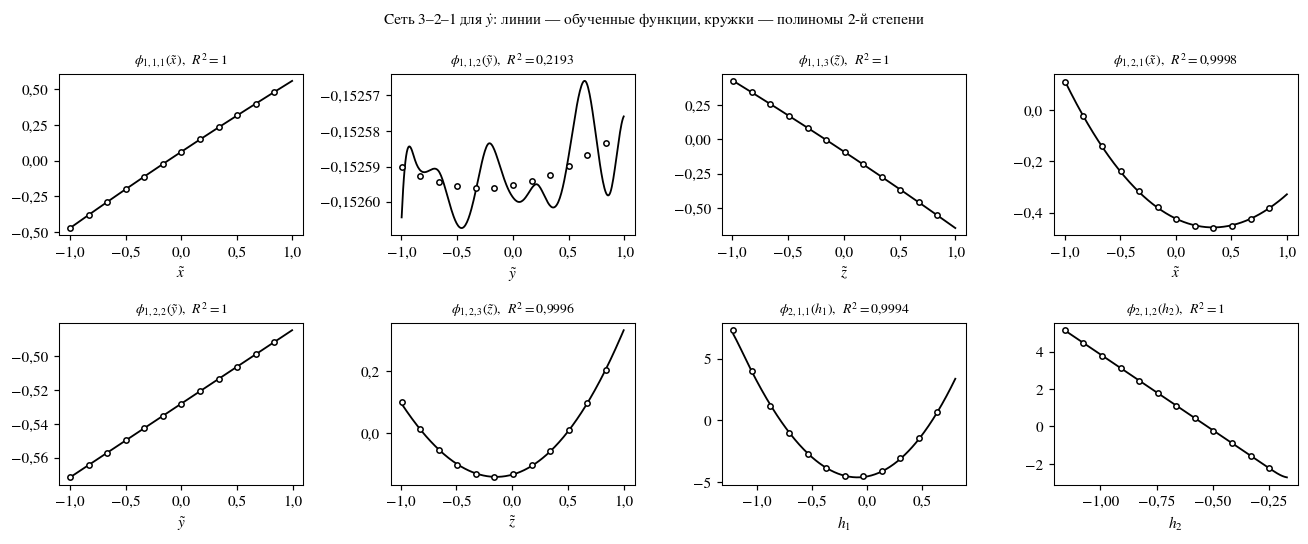

In [8]:
def layer_inputs(net, X):
    xs = [X]
    for L in net.layers[:-1]: xs.append(L.forward(xs[-1]))
    return xs

net = nets_B[1]
ins = layer_inputs(net, DB['train'][0])
fig, axs = plt.subplots(2, 4, figsize=(12, 5))
panels = [(0, j, i) for j in range(2) for i in range(3)] + [(1, 0, 0), (1, 0, 1)]
for ax, (l, j, i) in zip(axs.flat, panels):
    L = net.layers[l]; zin = ins[l][:, i]
    z = np.linspace(zin.min(), zin.max(), 300); p = L.edge(j, i, z)
    c = np.polyfit(z, p, 2); q = np.polyval(c, z)
    r2 = 1 - np.sum((q - p) ** 2) / max(np.sum((p - p.mean()) ** 2), 1e-30)
    ax.plot(z, p, 'k-', lw=1.2); ax.plot(z[::25], q[::25], 'o', mfc='white', mec='black', ms=3.5)
    lab = ['\\tilde x', '\\tilde y', '\\tilde z'][i] if l == 0 else f'h_{i + 1}'
    ax.set_title(f'$\\phi_{{{l + 1},{j + 1},{i + 1}}}({lab})$,  $R^2={mnum(r2, 4)}$', fontsize=9)
    ax.set_xlabel(f'${lab}$')
fig.suptitle(r'Сеть 3–2–1 для $\dot y$: линии — обученные функции, кружки — полиномы 2-й степени', fontsize=10)
fig.tight_layout(); plt.show()

Почти все функции хорошо приближаются параболами или прямыми: сеть «нашла», что поле квадратичное. Низкий $R^2$ бывает у почти постоянных функций — их вклад мал, и такие связи можно удалить (прореживание, п. 4.3.4).

**Символизация в два шага.**
1. Каждую функцию на связи заменяем подобранным полиномом второй степени. Композиция полиномов — снова полином; раскроем его и получим коэффициенты при мономах до 4-й степени (в физических переменных $x,y,z$).
2. Мономы с заметными коэффициентами оставляем как *гипотезу о структуре*, а их коэффициенты **уточняем МНК** по данным — так символизация превращает сеть в модель с фиксированным базисом (глава 3).

In [9]:
# Мономы от x, y, z и запись уравнений — нужны для символизации
def monomials(deg):
    return [m for d in range(deg + 1) for m in itertools.combinations_with_replacement(range(3), d)]
def mono_matrix(P, mons):
    return np.stack([np.prod(P[:, list(m)], axis=1) if m else np.ones(len(P)) for m in mons], axis=1)
def mono_name(m):
    return ''.join('xyz'[k] + (f'^{m.count(k)}' if m.count(k) > 1 else '') for k in sorted(set(m))) or '1'
def equations(coef_cols, mons):
    lines = []
    for j in range(3):
        parts = []
        for c, m in zip(coef_cols[:, j], mons):
            if c == 0: continue
            n = mono_name(m); a = abs(c)
            body = (mnum(a, 5) if (n == '1' or abs(a - 1) > 1e-6) else '') + ('' if n == '1' else ('\\,' if abs(a - 1) > 1e-6 else '') + n)
            sign = ('-' if c < 0 else '') if not parts else (' - ' if c < 0 else ' + ')
            parts.append(sign + body)
        lines.append(f'$${NAMES[j]} = {"".join(parts)}$$')
    return '\n'.join(lines)

def symbolic_net(net, X, D):
    # сеть, в которой каждая функция на связи заменена полиномом 2-й степени
    ins = layer_inputs(net, D['train'][0]); out = X
    for l, L in enumerate(net.layers):
        Y = np.zeros((len(out), L.nout))
        for i in range(L.nin):
            z = np.linspace(ins[l][:, i].min(), ins[l][:, i].max(), 300)
            for j in range(L.nout):
                Y[:, j] += np.polyval(np.polyfit(z, L.edge(j, i, z), 2), out[:, i])
        out = Y
    return out[:, 0]

MONS4 = monomials(4)
Q = np.random.default_rng(9).uniform(LO, HI, (5000, 3))
MQ = mono_matrix(Q, MONS4)

def kan_to_equations(nets, D, thr=0.02):
    # шаг 1: раскрытие полиномиальной сети в мономы до 4-й степени
    coef_raw = np.zeros((len(MONS4), 3))
    for j in range(3):
        coef_raw[:, j] = np.linalg.lstsq(MQ, symbolic_net(nets[j], norm(Q), D) * SCALE[j], rcond=None)[0]
    # шаг 2: оставляем мономы, вклад которых в разброс значений больше thr, и уточняем коэффициенты МНК
    #        по обучающим данным D (свободный член оставляем всегда)
    contrib = np.abs(coef_raw) * MQ.std(0)[:, None] / SCALE[None, :]
    keep = contrib > thr; keep[0, :] = True
    coef_ref = np.zeros_like(coef_raw)
    Theta = mono_matrix(D['P_train'], MONS4)
    for j in range(3):
        coef_ref[keep[:, j], j] = np.linalg.lstsq(Theta[:, keep[:, j]], D['dX_train'][:, j], rcond=None)[0]
    coef_ref[np.abs(coef_ref) < 1e-6] = 0
    return coef_raw, coef_ref

coef_raw, coef_ref = kan_to_equations(nets_B, DB)

TRUE = {0: {'x': -10, 'y': 10}, 1: {'x': 28, 'y': -1, 'xz': -1}, 2: {'xy': 1, 'z': -8 / 3}}
rows = ''
for m_idx, m in enumerate(MONS4):
    if len(m) == 0 or len(m) > 2: continue
    n = mono_name(m)
    rows += f'| ${n}$ | ' + ' | '.join(f'{num(coef_raw[m_idx, j])} → **{num(coef_ref[m_idx, j], 5)}** ({num(TRUE[j].get(n, 0), 5)})'
                                   for j in range(3)) + ' |\n'
high = [k for k, m in enumerate(MONS4) if len(m) > 2]
note = (f'\n\nМономы 3-й и 4-й степени: наибольший коэффициент после раскрытия — {num(np.abs(coef_raw[high]).max())}, '
        f'после уточнения — {num(np.abs(coef_ref[high]).max())}. Свободный член после уточнения: '
        + ', '.join(num(coef_ref[0, j]) for j in range(3)) + '.')
display(Markdown('Коэффициенты при мономах: *после раскрытия полиномов* → **после уточнения МНК** (в скобках — истинное значение)\n\n'
                 '| Моном | $\\dot x$ | $\\dot y$ | $\\dot z$ |\n|---|---|---|---|\n' + rows + note))
display(Markdown('**Восстановленные уравнения:**\n' + equations(np.where(np.abs(coef_ref) < 1e-3, 0, coef_ref), MONS4)))

Коэффициенты при мономах: *после раскрытия полиномов* → **после уточнения МНК** (в скобках — истинное значение)

| Моном | $\dot x$ | $\dot y$ | $\dot z$ |
|---|---|---|---|
| $x$ | -10 → **-10** (-10) | 27,5 → **28** (28) | 2,39 → **0** (0) |
| $y$ | 10 → **10** (10) | -0,997 → **-1** (-1) | 2,01 → **0** (0) |
| $z$ | 0,00149 → **0** (0) | 2,49 → **0** (0) | -2,68 → **-2,6667** (-2,6667) |
| $x^2$ | 5,26e-06 → **0** (0) | -0,0514 → **0** (0) | -0,0514 → **0** (0) |
| $xy$ | 1,14e-11 → **0** (0) | -0,00031 → **0** (0) | 0,966 → **1** (1) |
| $xz$ | -7,26e-12 → **0** (0) | -0,898 → **-1** (-1) | 0,000309 → **0** (0) |
| $y^2$ | -1,33e-05 → **0** (0) | 4,08e-05 → **0** (0) | -0,0356 → **0** (0) |
| $yz$ | -6,84e-12 → **0** (0) | -0,0011 → **0** (0) | 0,000241 → **0** (0) |
| $z^2$ | -3e-05 → **0** (0) | -0,113 → **0** (0) | 0,000105 → **0** (0) |


Мономы 3-й и 4-й степени: наибольший коэффициент после раскрытия — 0,00657, после уточнения — 0. Свободный член после уточнения: 0, 0, 0.

**Восстановленные уравнения:**
$$\dot x = -10\,x + 10\,y$$
$$\dot y = 28\,x - y - xz$$
$$\dot z = -2{,}6667\,z + xy$$

После раскрытия полиномов коэффициенты лишь приблизительно похожи на истинные, и появляются лишние мономы: сеть приближает поле с ошибкой около 1 %, а при раскрытии ошибки складываются. Но **структура** угадана: в разложении доминируют $x,y$ для $\dot x$; $x,y,xz$ для $\dot y$; $xy,z$ для $\dot z$. Уточнение коэффициентов МНК на этих мономах даёт точные уравнения Лоренца. Так работает символизация на практике: сеть предлагает структуру, МНК находит коэффициенты, а итог проверяется на независимых данных.

<a id="s6"></a>
## 6. Интегрирование выученных систем

Проинтегрируем из одной начальной точки на аттракторе три системы: истинную, «сырую» сеть KAN (обученную на данных B) и восстановленные уравнения.

интегрирование: 9 с


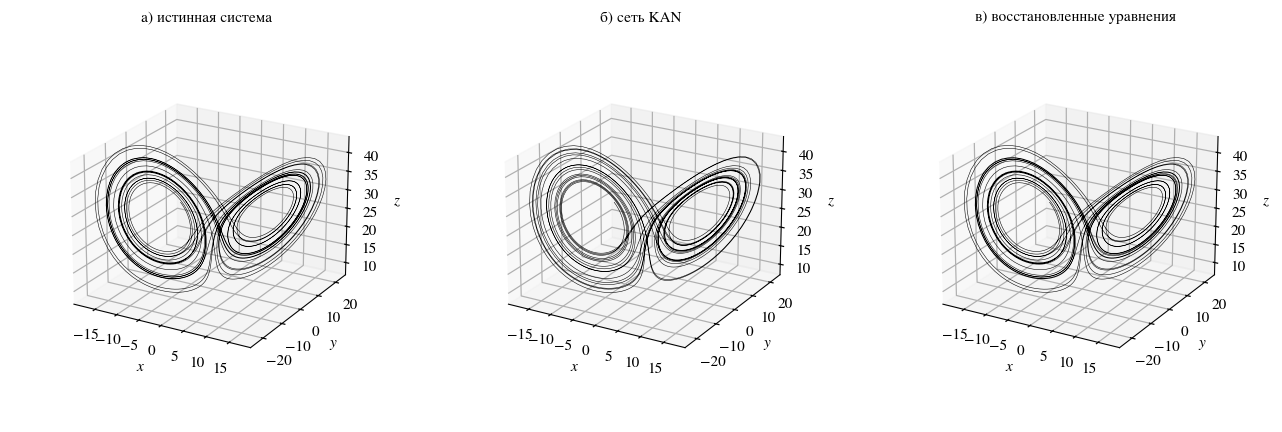

In [10]:
def kan_field(s):
    X = norm(np.atleast_2d(s))
    return np.array([nets_B[j].forward(X)[0, 0] * SCALE[j] for j in range(3)])

def sym_field(s):
    return (mono_matrix(np.atleast_2d(s), MONS4) @ coef_ref)[0]

s0 = traj[123]; N = 2500
t0 = time.perf_counter()
T_true = rk4(lorenz, s0, DT, N); T_kan = rk4(kan_field, s0, DT, N); T_sym = rk4(sym_field, s0, DT, N)
print(f'интегрирование: {time.perf_counter() - t0:.0f} с')

fig = plt.figure(figsize=(12, 3.9))
for k, (T, ttl) in enumerate([(T_true, 'а) истинная система'), (T_kan, 'б) сеть KAN'), (T_sym, 'в) восстановленные уравнения')]):
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    ax.plot(*T.T, color='black', lw=0.35); ax.set_title(ttl, fontsize=10); ax.view_init(elev=22, azim=-60)
    ax.set_xlabel('$x$'); ax.set_ylabel('$y$'); ax.set_zlabel('$z$'); ax.set_box_aspect(None, zoom=0.8)
fig.tight_layout(); plt.show()

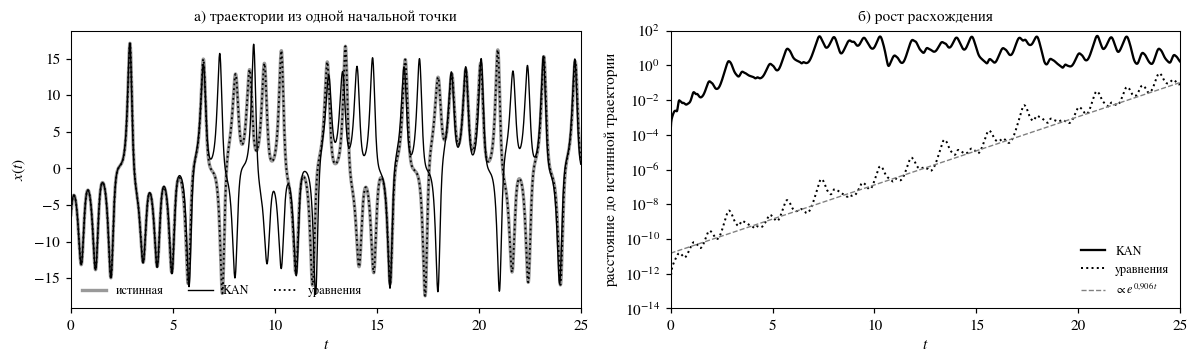

Расхождение с истинной траекторией превышает 1: у сети KAN — при $t\approx2{,}75$; у восстановленных уравнений — не превышает 1 за всё время интегрирования ($t\le25$; к концу — 0,088).

In [11]:
tt = np.arange(N + 1) * DT
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axs[0]
ax.plot(tt, T_true[:, 0], '-', color='0.6', lw=2.2, label='истинная')
ax.plot(tt, T_kan[:, 0], 'k-', lw=0.9, label='KAN')
ax.plot(tt, T_sym[:, 0], 'k:', lw=1.2, label='уравнения')
ax.set_xlim(0, 25); ax.set_xlabel('$t$'); ax.set_ylabel('$x(t)$'); ax.legend(fontsize=8, loc='lower left', ncol=3)
ax.set_title('а) траектории из одной начальной точки', fontsize=10)
ax = axs[1]
for T, st, lab in [(T_kan, dict(color='black', ls='-'), 'KAN'), (T_sym, dict(color='black', ls=':', lw=1.3), 'уравнения')]:
    ax.semilogy(tt, np.maximum(np.linalg.norm(T - T_true, axis=1), 1e-16), label=lab, **st)
lam = 0.906                                                    # старший показатель Ляпунова системы
e0 = np.linalg.norm(T_sym[100] - T_true[100])
ax.semilogy(tt, e0 * np.exp(lam * (tt - 1.0)), color='0.5', ls='--', lw=0.9, label=r'$\propto e^{0{,}906\,t}$')
ax.set_ylim(1e-14, 1e2); ax.set_xlim(0, 25); ax.set_xlabel('$t$'); ax.set_ylabel('расстояние до истинной траектории')
ax.legend(fontsize=8, loc='lower right'); ax.set_title('б) рост расхождения', fontsize=10)
fig.tight_layout(); plt.show()

def t_sep(T, thr=1.0):
    d = np.linalg.norm(T - T_true, axis=1); i = np.argmax(d > thr)
    return f'при $t\\approx{mnum(tt[i], 3)}$' if d[i] > thr else f'не превышает 1 за всё время интегрирования ($t\\le{mnum(tt[-1], 3)}$; к концу — {num(d[-1], 2)})'
display(Markdown(f'Расхождение с истинной траекторией превышает 1: у сети KAN — {t_sep(T_kan)}; у восстановленных уравнений — {t_sep(T_sym)}.'))

* **Аттрактор сеть воспроизводит**: «бабочка» на рис. (б) имеет ту же форму и размеры, что и истинная. Значит, выученное поле верно описывает геометрию динамики.
* **Траекторию сеть предсказывает лишь недолго.** Ошибка поля около 1 % — и через несколько единиц времени траектории полностью расходятся. Скорость роста расхождения почти не зависит от модели: её задаёт старший показатель Ляпунова системы ($\lambda\approx0{,}906$, пунктир). Это свойство хаоса, а не недостаток сети: восстановленные уравнения с ошибкой коэффициентов на уровне округления тоже расходятся с истинной траекторией с той же скоростью, только начинают с ошибки порядка $10^{-12}$ и поэтому дольше остаются близкими.

<a id="s7n"></a>
## 7. Опыт с шумом

Повторим обучение сетей на данных B и символизацию при шуме скоростей 1 % и 5 % от стандартного отклонения каждой компоненты (параметр `NOISE_DERIV`). Тестовые данные остаются точными. Сравниваются коэффициенты при истинных мономах, «лишние» мономы, которые попали в восстановленные уравнения, и ошибка самой сети. Как ведёт себя при таком шуме метод SINDy, разобрано в шагах 4–5 блокнота главы 3 `ch03_Lorenz_SINDy.ipynb`.

In [12]:
LEVELS = [0.0, 0.01, 0.05]
TERMS = [(0, 'x'), (0, 'y'), (1, 'x'), (1, 'y'), (1, 'xz'), (2, 'xy'), (2, 'z')]
IDX4 = {mono_name(m): k for k, m in enumerate(MONS4)}

def spurious(coef):
    # число и наибольший модуль коэффициентов при мономах, которых нет в истинных уравнениях
    vals = [abs(coef[k, j]) for j in range(3) for n, k in IDX4.items() if n not in TRUE[j] and coef[k, j] != 0]
    return len(vals), (max(vals) if vals else 0.0)

t0 = time.perf_counter(); noise_res = {}
for lev in LEVELS:
    if lev == NOISE_DERIV and NOISE_STATE == 0.0:
        nets_n, Db = nets_B, DB                              # этот уровень уже обучен в разделе 4
    else:
        Db = split(P_B, lev, 0.0, NOISE_SEED); nets_n = train_B_nets(Db)
    _, kref = kan_to_equations(nets_n, Db)
    errB = [rmse(nets_n[j].forward(DB['test'][0])[:, 0], DB['test'][1][:, j]) for j in range(3)]
    noise_res[lev] = dict(kan=kref, errB=errB)
print(f'обучено за {time.perf_counter() - t0:.0f} с')

pct = lambda l: f'{num(100 * l)} %'
head = '| Член | Истина | ' + ' | '.join(f'шум {pct(l)}' for l in LEVELS) + ' |\n|---|---|' + '---|' * len(LEVELS) + '\n'
rows = ''.join(f'| ${NAMES[j]}$: ${n}$ | {num(TRUE[j][n], 4)} | ' + ' | '.join(num(noise_res[l]['kan'][IDX4[n], j], 4) for l in LEVELS) + ' |\n'
               for j, n in TERMS)
rows += '| лишние мономы | 0 | ' + ' | '.join('{} (макс. {})'.format(*(lambda k, mx: (k, num(mx, 2)))(*spurious(noise_res[l]['kan']))) for l in LEVELS) + ' |\n'
rows += '| RMSE сетей на точном тесте B | — | ' + ' | '.join(', '.join(num(e, 2) for e in noise_res[l]['errB']) for l in LEVELS) + ' |\n'
display(Markdown('Коэффициенты восстановленных уравнений (KAN → символизация → МНК):\n\n' + head + rows))

обучено за 130 с


Коэффициенты восстановленных уравнений (KAN → символизация → МНК):

| Член | Истина | шум 0 % | шум 1 % | шум 5 % |
|---|---|---|---|---|
| $\dot x$: $x$ | -10 | -10 | -9,999 | -9,997 |
| $\dot x$: $y$ | 10 | 10 | 10 | 10,01 |
| $\dot y$: $x$ | 28 | 28 | 28 | 28,02 |
| $\dot y$: $y$ | -1 | -1 | -0,9997 | -0,9155 |
| $\dot y$: $xz$ | -1 | -1 | -0,9999 | -0,9994 |
| $\dot z$: $xy$ | 1 | 1 | 1 | 0,9997 |
| $\dot z$: $z$ | -2,667 | -2,667 | -2,666 | -2,755 |
| лишние мономы | 0 | 0 (макс. 0) | 18 (макс. 0,31) | 26 (макс. 1,4) |
| RMSE сетей на точном тесте B | — | 0,0014, 0,0021, 0,012 | 0,0028, 0,0047, 0,016 | 0,012, 0,02, 0,029 |


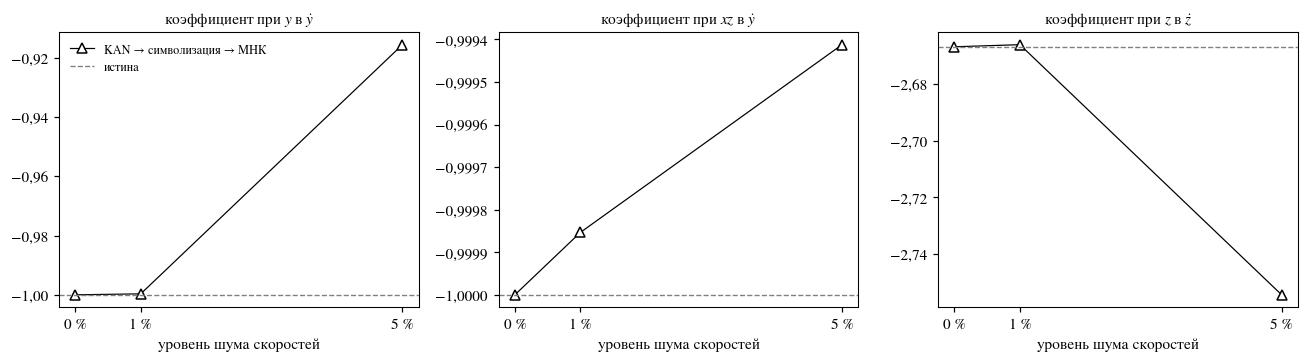

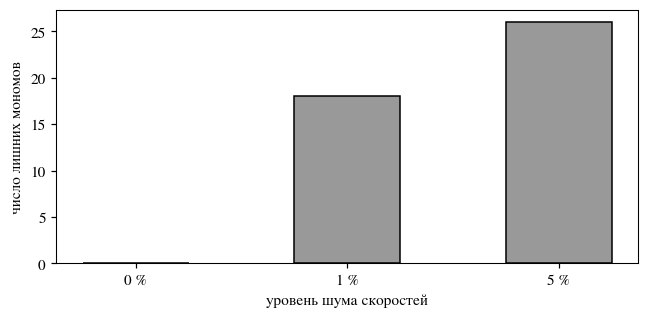

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (j, n) in zip(axs, [(1, 'y'), (1, 'xz'), (2, 'z')]):
    vals = [noise_res[l]['kan'][IDX4[n], j] for l in LEVELS]
    ax.plot([100 * l for l in LEVELS], vals, 'k^-', mfc='white', ms=7, lw=0.8, label='KAN → символизация → МНК')
    ax.axhline(TRUE[j][n], color='0.5', ls='--', lw=0.9, label='истина')
    ax.set_xticks([100 * l for l in LEVELS]); ax.set_xticklabels([pct(l) for l in LEVELS])
    ax.ticklabel_format(axis='y', useOffset=False)
    ax.set_xlabel('уровень шума скоростей'); ax.set_title(f'коэффициент при ${n}$ в ${NAMES[j]}$', fontsize=10)
axs[0].legend(fontsize=8); fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar([pct(l) for l in LEVELS], [spurious(noise_res[l]['kan'])[0] for l in LEVELS], color='0.6', edgecolor='black', width=0.5)
ax.set_ylabel('число лишних мономов'); ax.set_xlabel('уровень шума скоростей')
fig.tight_layout(); plt.show()

Что показывает опыт:
* **Структура находится и при шуме.** Коэффициенты при истинных мономах остаются близкими к истине: при 1 % — с точностью до долей процента, при 5 % заметно отклоняются лишь отдельные коэффициенты (см. таблицу и рисунок).
* **Но появляются лишние мономы, и их число растёт с шумом.** Сеть приближает шум вместе с полем, раскрытие полиномов превращает эти погрешности в ложные вклады 3-й и 4-й степени выше порога отбора, а уточнение МНК делит между ними часть шума. Растёт и ошибка самих сетей на точном тесте.
* **Практический вывод.** При шумных данных результат символизации — это *гипотеза о структуре*, которую надо прорежать: повышать порог отбора `thr` функции `kan_to_equations`, ограничивать степень полиномов, проверять уравнения на независимых данных. Выбор порога — решение человека, как и правило выбора при близких $R^2$ в примере 2 блокнота `KAN_примеры.ipynb`. Метод SINDy с узкой библиотекой мономов переносит такой шум заметно лучше (блокнот главы 3), но только потому, что вид функций ему известен заранее.
* **Шум состояния** (параметр `NOISE_STATE`) опаснее шума скоростей: он попадает в регрессоры — мономы $x$, $xz$, … — и смещает оценки МНК (эффект «ошибок в переменных»). Проверьте это, задав `NOISE_STATE = 0.002` в начале раздела 2 и перезапустив блокнот.

<a id="s7"></a>
## 8. Выводы

| Вопрос | Ответ на примере системы Лоренца |
|---|---|
| Нужна ли сеть, если вид правых частей известен? | Нет: МНК с полиномиальной библиотекой восстанавливает уравнения точно и одной операцией, даже по данным только с аттрактора (блокнот главы 3) |
| Что даёт сеть, если вид неизвестен? | Подсказывает структуру: какие компоненты аддитивны, какие требуют композиции, какие функции стоят на связях |
| Достаточно ли данных с аттрактора? | Для гибкой модели — нет: аттрактор не определяет поле в остальной области; нужен эксперимент, покрывающий область |
| Как получить формулу? | Символизация предлагает мономы, МНК уточняет их коэффициенты, независимые данные подтверждают результат |
| Можно ли предсказать хаотическую траекторию? | Только на время порядка $\lambda^{-1}\ln(\text{допуск}/\text{ошибка})$; воспроизводится аттрактор, а не конкретная траектория |

Сеть Колмогорова–Арнольда здесь — инструмент **поиска гипотезы**, а не замена МНК. Пример оправдывает её применение, если правые части неизвестны и не обязательно полиномиальны: например, при трении, насыщении или других нелинейностях, для которых нет готовой библиотеки.

**Задания.**
1. Получите скорости численным дифференцированием траектории (центральной разностью) вместо точных значений. Сравните ошибку дифференцирования с уровнями шума раздела 7 и повторите символизацию. Сравните с шагами 4–5 блокнота главы 3, где тот же вопрос разобран для SINDy.
2. Обучите сеть 3–3–1 для $\dot y$. Выполните прореживание: какие связи можно удалить без потери точности?
3. Замените $\dot x=\sigma(y-x)$ на $\dot x=\sigma\tanh(y-x)$. МНК с полиномиальной библиотекой с этим не справится (блокнот главы 3, шаг 8 и задание 5). Справится ли сеть с символизацией?